# Baby Qwen 1/3: Pretraining Baby Qwen2.5 from Scratch

**Target Architecture**: Scaled-down Qwen2.5 (~42M parameters)  
**Curriculum Goals**:
- **Step 1: Pretraining from Scratch** (`week4/BabyQwen-1-Pretraining.ipynb`) — Causal language modeling on raw text to build a base model (*raw text → language*).
- **Step 2: Supervised Fine-Tuning** (`week5/BabyQwen-2-FineTuning.ipynb`) — ChatML template & response-only loss to teach instruction-following (*language → follows instructions*).
- **Step 3: Knowledge Injection & LoRA** (`week5/BabyQwen-3-KnowledgeInjection.ipynb`) — Parameter-efficient fine-tuning to inject new domain facts into the tuned model (*follows instructions → knows new facts*).

**Current Focus**: **Step 1** — Design, initialize, pretrain, and save a miniature causal language model from scratch.

The model uses the modern architectural innovations of **Qwen2.5**:
- **SwiGLU Activations** in the feed-forward blocks
- **Grouped-Query Attention (GQA)** for efficient inference
- **Rotary Positional Embeddings (RoPE)** with high base frequency ($\\theta = 10^6$)
- **RMSNorm** for pre-normalization stability
- **Tied Word Embeddings** to minimize memory on consumer devices

| Specification | Value | Notes |
|---|---|---|
| Architecture | Decoder-only Transformer (`Qwen2ForCausalLM`) | Native Hugging Face architecture |
| Total Parameters | ~41.8 Million | Trainable on free Colab T4 / Apple Silicon / CPU |
| Hidden Dimension ($d$) | 256 | Compact representation |
| Layers ($L$) | 4 | Fast forward/backward passes in class |
| Attention Heads ($H_Q / H_{KV}$) | 8 Query / 2 Key-Value | 4:1 GQA ratio |
| Max Context Window | 1,024 tokens | Scalable up to 32k via RoPE |
| Pretraining Data | TinyStories (~1.3M tokens) + held-out validation split | Real corpus, so the model must generalize |
| Destination | `./baby_qwen_pretrained` | Passed directly to Step 2 (`BabyQwen-2-FineTuning.ipynb`) |

In [1]:
%pip install transformers datasets torch accelerate -q
import os, math, time
import torch
from transformers import AutoTokenizer, Qwen2Config, Qwen2ForCausalLM
import matplotlib.pyplot as plt

# Device selection: CUDA -> MPS -> CPU
device = 'cuda' if torch.cuda.is_available() else ('mps' if torch.backends.mps.is_available() else 'cpu')
print(f'PyTorch Version : {torch.__version__}')
print(f'Compute Device  : {device.upper()}')


PyTorch Version : 2.11.0+cu130
Compute Device  : CUDA


---
## 1. Architecture Design — Qwen2Config

We configure our Baby Qwen using Hugging Face's native `Qwen2Config` class.
Key hyperparameter decisions:
1. **`hidden_size = 256`**: The primary embedding dimension $d$.
2. **`intermediate_size = 768`**: SwiGLU FFN projection size (approximately $\frac{8}{3} \times d$).
3. **`num_attention_heads = 8` & `num_key_value_heads = 2`**: Grouped-Query Attention with 4 query heads per key-value head, reducing KV cache memory by $4\times$.
4. **`rope_theta = 1000000.0`**: Qwen2.5 base frequency supporting long-context extrapolation.
5. **`tie_word_embeddings = True`**: Ties the input embedding weights with the output LM prediction head, saving ~38M parameters.

> **Where do the parameters go?** With Qwen2.5's 151,665-token vocabulary, the embedding table alone is $151{,}665 \times 256 \approx 38.8$M parameters, about **93%** of the model. The 4 Transformer layers hold only ~3M. Small models spend most of their budget on the vocabulary, which is why tying input and output embeddings matters so much here.

In [2]:
# Load the Qwen2.5 tokenizer (BPE, 151k vocab) from the Hugging Face Hub
tokenizer = AutoTokenizer.from_pretrained('Qwen/Qwen2.5-0.5B')

# Ensure pad token is set
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

# Instantiate Baby Qwen Configuration
baby_config = Qwen2Config(
    vocab_size=len(tokenizer),
    hidden_size=256,
    intermediate_size=768,
    num_hidden_layers=4,
    num_attention_heads=8,
    num_key_value_heads=2,
    max_position_embeddings=1024,
    rope_theta=1000000.0,
    tie_word_embeddings=True,
)

# Initialize model with random weights
torch.manual_seed(42)
model = Qwen2ForCausalLM(baby_config).to(device)

# Parameter breakdown
emb_params = sum(p.numel() for p in model.model.embed_tokens.parameters())
layer_params = sum(p.numel() for p in model.model.layers.parameters())
total_params = sum(p.numel() for p in model.parameters())

print('=' * 55)
print(f"Baby Qwen2.5 Architecture Summary:")
print(f"  Embedding Table   : {emb_params:>12,} params ({emb_params/total_params*100:.1f}%)")
print(f"  4x Transformer    : {layer_params:>12,} params ({layer_params/total_params*100:.1f}%)")
print(f"  Total Parameters  : {total_params:>12,} params")
print('=' * 55)

config.json:   0%|          | 0.00/681 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.23k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

Baby Qwen2.5 Architecture Summary:
  Embedding Table   :   38,826,240 params (92.8%)
  4x Transformer    :    3,018,240 params (7.2%)
  Total Parameters  :   41,844,736 params


---
## 2. Tokenizer & Data Pipeline

### Why TinyStories?
Introduced by Eldan & Li (Microsoft Research, 2023), **TinyStories** is a synthetic corpus generated by GPT-3.5 and GPT-4 specifically designed to prove that small models (<50M parameters) can learn coherent English without needing billions of parameters or massive web crawls:
- **Low Lexical & Syntactic Entropy**: Restricted to a 3- to 4-year-old vocabulary (~3,000–4,000 words like *dog, ball, happy, park*). Unlike noisy web scrapes (C4, Common Crawl), there are no HTML tags, legal disclaimers, or jargon, allowing a compact ~42M model to saturate the distribution quickly.
- **High Semantic Density**: Every story has a complete narrative arc with a beginning, middle, and end, plus simple cause-and-effect reasoning.
- **Fast Convergence on Consumer Hardware**: While web pretraining takes hundreds of millions of tokens before words stop looking like gibberish, TinyStories enables Baby Qwen to reach fluent grammar within **~1.2M tokens (600 steps)** in ~5 minutes on a laptop or ~90 seconds on a free Colab GPU.

Data preparation steps:
1. **Tokenization**: Converting raw text into token IDs using Qwen2.5 BPE.
2. **Packing & Chunking**: Concatenating documents with `<|endoftext|>` delimiters and slicing into fixed-length context windows ($T=256$).
3. **Train / Validation Split**: Validation stories come from the dataset's separate `validation` split, so the model never trains on them. Validation loss is the real signal of whether the model is learning language or just memorizing.
4. **Causal Masking**: Handled inside `Qwen2ForCausalLM` via lower-triangular attention.

> **Use your own data.** To pretrain on your own text instead, set `CUSTOM_TRAIN` in the next cell to a list of strings or a file pattern like `'my_data/*.txt'`. Everything after that cell works unchanged. Expect the model to learn the *style and vocabulary* of your text, not world knowledge: at ~1M tokens it is a tiny language model.

In [3]:
from datasets import load_dataset
import glob

SEQ_LEN = 256
N_TRAIN_STORIES = 6_000    # ~1.3M tokens
N_VAL_STORIES = 500        # held-out, never trained on

# ── USE YOUR OWN DATA (optional) ───────────────────────────────────────────
# CUSTOM_TRAIN: a list of text documents (strings), or a glob such as 'my_data/*.txt'
#               (one document per file). Leave as None to train on TinyStories.
# CUSTOM_VAL  : optional held-out documents in the same format. If None, the last
#               10% of CUSTOM_TRAIN is held out for validation.
# Each training step uses 8 x 256 = 2,048 tokens, so raise TOTAL_STEPS (optimizer cell)
# in proportion to your corpus size.
CUSTOM_TRAIN = None
CUSTOM_VAL = None

def load_custom(src):
    if isinstance(src, str):
        src = [open(p, encoding='utf-8').read() for p in sorted(glob.glob(src))]
    docs = [d.strip() for d in src if isinstance(d, str) and d.strip()]
    assert docs, 'No non-empty text documents found. Check your path or your list of strings.'
    return docs

def pack(stories):
    # Tokenize stories, join with EOS, slice into fixed-length chunks
    ids = []
    for text in stories:
        ids.extend(tokenizer.encode(text) + [tokenizer.eos_token_id])
    n = len(ids) // SEQ_LEN
    assert n > 0, f'Only {len(ids)} tokens: need at least {SEQ_LEN} to form one training sequence.'
    return torch.tensor(ids[: n * SEQ_LEN], dtype=torch.long).view(n, SEQ_LEN)

def take(split, n):
    ds = load_dataset('roneneldan/TinyStories', split=split, streaming=True)
    return [ex['text'] for _, ex in zip(range(n), ds)]

t0 = time.time()
if CUSTOM_TRAIN is not None:
    train_docs = load_custom(CUSTOM_TRAIN)
    if CUSTOM_VAL is None:
        cut = max(1, int(0.9 * len(train_docs)))
        train_docs, val_docs = train_docs[:cut], train_docs[cut:]
        assert val_docs, 'Need at least 2 documents so some can be held out for validation.'
    else:
        val_docs = load_custom(CUSTOM_VAL)
    train_tensor, val_tensor = pack(train_docs), pack(val_docs)
    if train_tensor.numel() < 100_000:
        print('Warning: under 100k training tokens. A model this size will memorize it rather than generalize.')
else:
    train_tensor = pack(take('train', N_TRAIN_STORIES))
    val_tensor = pack(take('validation', N_VAL_STORIES))

print(f'Train: {train_tensor.numel():,} tokens in {train_tensor.shape[0]:,} sequences of L={SEQ_LEN}')
print(f'Val  : {val_tensor.numel():,} tokens in {val_tensor.shape[0]:,} sequences (held out)')
print(f'Data prep took {time.time() - t0:.0f}s')


README.md:   0%|          | 0.00/1.06k [00:00<?, ?B/s]

Train: 1,187,072 tokens in 4,637 sequences of L=256
Val  : 97,024 tokens in 379 sequences (held out)
Data prep took 14s


---
## 3. Autoregressive Causal Loss & Perplexity

During pretraining, the model receives token sequence $x_{1:T}$ and predicts targets $x_{2:T+1}$:

$$\mathcal{L} = -\frac{1}{T-1}\sum_{t=1}^{T-1} \log P(x_{t+1} \mid x_{1:t})$$

- **Initial Expected Loss**: For randomly initialized weights over vocabulary size $V$, the expected uniform cross-entropy is:
$$\mathcal{L}_{\text{uniform}} = \ln(V) = \ln(151{,}665) \approx 11.93$$
- **Perplexity**: $\text{PPL} = \exp(\mathcal{L})$. As pretraining progresses, perplexity decreases from ~150,000 down as the model learns. On TinyStories a model this small typically reaches a validation perplexity in the low tens, not near 1. A perplexity near 1 would mean memorization.

In [4]:
# Verify initial loss matches theoretical uniform cross-entropy
sample_batch = train_tensor[:2].to(device)

with torch.no_grad():
    outputs = model(input_ids=sample_batch, labels=sample_batch)
    initial_loss = outputs.loss.item()
    initial_ppl = math.exp(initial_loss)

expected_loss = math.log(len(tokenizer))
print(f'Vocabulary Size (V)        : {len(tokenizer):,}')
print(f'Theoretical Random Loss ln(V): {expected_loss:.4f}')
print(f'Actual Initial Model Loss  : {initial_loss:.4f}')
print(f'Initial Perplexity         : {initial_ppl:,.1f}')
assert abs(initial_loss - expected_loss) < 0.2, 'Model initialization deviates from theoretical uniform distribution!'


Vocabulary Size (V)        : 151,665
Theoretical Random Loss ln(V): 11.9294
Actual Initial Model Loss  : 11.9860
Initial Perplexity         : 160,498.7


---
## 4. Pretraining Optimizer & Cosine Schedule

Modern LLM pretraining relies on **AdamW** with cosine decay:
- **Optimizer**: `torch.optim.AdamW(model.parameters(), lr=8e-4, betas=(0.9, 0.95), weight_decay=0.01)`
- **Linear Warmup**: 5% of total training steps (30 of 600) to prevent gradient explosions while the weights are still random.
- **Cosine Annealing**: Decays the learning rate down to 10% of $\eta_{\max}$.
- **Gradient Clipping**: Norm capped at $1.0$ (applied inside the training loop below).

In [5]:
# Optimizer with decoupled weight decay
LEARNING_RATE = 8e-4
WEIGHT_DECAY = 0.01
TOTAL_STEPS = 600
WARMUP_STEPS = int(0.05 * TOTAL_STEPS)   # 5% of training (30 steps for 600)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    betas=(0.9, 0.95),
    weight_decay=WEIGHT_DECAY,
)

# Learning rate schedule function
def get_lr(step: int) -> float:
    if step < WARMUP_STEPS:
        return LEARNING_RATE * (step + 1) / WARMUP_STEPS
    progress = (step - WARMUP_STEPS) / max(1, TOTAL_STEPS - WARMUP_STEPS)
    coeff = 0.5 * (1.0 + math.cos(math.pi * progress))
    return 0.1 * LEARNING_RATE + coeff * (0.9 * LEARNING_RATE)

print(f'Optimizer: AdamW (lr={LEARNING_RATE}, weight_decay={WEIGHT_DECAY})')
print(f'Schedule : {WARMUP_STEPS} warmup steps -> {TOTAL_STEPS} total steps')

Optimizer: AdamW (lr=0.0008, weight_decay=0.01)
Schedule : 30 warmup steps -> 600 total steps


---
## 5. Pretraining Loop Execution

We run the loop with a **held-out evaluation** every 50 steps:
1. Sample random mini-batches from the packed training tensor.
2. Forward pass with causal cross-entropy loss.
3. Backward pass, clip gradient norms to $1.0$, update weights, adjust learning rate.
4. Every 50 steps, compute loss and perplexity on the validation set. A train/val gap is the signature of overfitting.

Each step processes $8 \times 256 = 2{,}048$ tokens, so 600 steps is about 1.2M tokens, roughly one pass over the training data. On Apple Silicon this takes ~5 minutes (throughput is ~4k tokens/sec because the 151k-token vocabulary makes the output softmax expensive).

In [6]:
BATCH_SIZE = 8
EVAL_EVERY = 50
history = {'step': [], 'loss': [], 'ppl': [], 'lr': []}
val_history = {'step': [], 'loss': [], 'ppl': []}

@torch.no_grad()
def evaluate(max_batches=8):
    model.eval()
    losses = []
    for i in range(0, min(val_tensor.shape[0], max_batches * BATCH_SIZE), BATCH_SIZE):
        b = val_tensor[i : i + BATCH_SIZE].to(device)
        losses.append(model(input_ids=b, labels=b).loss.item())
    model.train()
    return sum(losses) / len(losses)

model.train()
print(f"Starting Baby Qwen2.5 Pretraining on {device.upper()}...")
print(f"{'Step':>5} | {'Train Loss':>10} | {'Val Loss':>8} | {'Val PPL':>9} | {'LR':>9} | {'Tokens/sec':>10}")
print('-' * 68)

t0_total = time.time()
total_tokens_trained = 0

for step in range(TOTAL_STEPS):
    t_step_start = time.time()

    # 1. Update learning rate
    lr = get_lr(step)
    for param_group in optimizer.param_groups:
        param_group['lr'] = lr

    # 2. Sample random mini-batch
    idx = torch.randint(0, train_tensor.shape[0], (BATCH_SIZE,))
    batch = train_tensor[idx].to(device)

    # 3. Forward pass (Qwen computes cross-entropy internally when labels are passed)
    optimizer.zero_grad()
    loss = model(input_ids=batch, labels=batch).loss

    # 4. Backward pass & gradient clipping
    loss.backward()
    torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
    optimizer.step()

    # 5. Telemetry
    step_tokens = BATCH_SIZE * SEQ_LEN
    total_tokens_trained += step_tokens
    current_loss = loss.item()  # .item() syncs the device, so the timing below is real
    tps = step_tokens / max(time.time() - t_step_start, 1e-4)

    history['step'].append(step)
    history['loss'].append(current_loss)
    history['ppl'].append(math.exp(min(current_loss, 20.0)))
    history['lr'].append(lr)

    if (step + 1) % EVAL_EVERY == 0 or step == 0:
        v_loss = evaluate()
        v_ppl = math.exp(min(v_loss, 20.0))
        val_history['step'].append(step)
        val_history['loss'].append(v_loss)
        val_history['ppl'].append(v_ppl)
        tps_str = f'{tps:>6.0f}' if step > 0 else '(warmup)'  # step 1 includes device warmup
        print(f"{step + 1:>5} | {current_loss:>10.4f} | {v_loss:>8.4f} | {v_ppl:>9.2f} | {lr:>9.2e} | {tps_str:>10}")

total_elapsed = time.time() - t0_total
print('-' * 68)
print(f"Pretraining completed in {total_elapsed:.0f}s | {total_tokens_trained:,} tokens ({total_tokens_trained / train_tensor.numel():.2f} epochs)")
print(f"Train loss: {history['loss'][0]:.3f} -> {history['loss'][-1]:.3f}")
print(f"Val   loss: {val_history['loss'][0]:.3f} -> {val_history['loss'][-1]:.3f}  (PPL {val_history['ppl'][0]:,.0f} -> {val_history['ppl'][-1]:.1f})")

Starting Baby Qwen2.5 Pretraining on CUDA...
 Step | Train Loss | Val Loss |   Val PPL |        LR | Tokens/sec
--------------------------------------------------------------------
    1 |    11.9968 |  11.9825 | 159937.11 |  2.67e-05 |   (warmup)
   50 |     6.0237 |   6.0420 |    420.72 |  7.98e-04 |      18254
  100 |     5.5333 |   5.0819 |    161.08 |  7.74e-04 |      17964
  150 |     4.5238 |   4.3885 |     80.52 |  7.25e-04 |      17924
  200 |     4.0230 |   4.0346 |     56.52 |  6.55e-04 |      17927
  250 |     4.1874 |   3.8123 |     45.26 |  5.68e-04 |      17965
  300 |     3.8846 |   3.6556 |     38.69 |  4.72e-04 |      18074
  350 |     3.9001 |   3.5608 |     35.19 |  3.73e-04 |      18006
  400 |     3.8566 |   3.4851 |     32.63 |  2.79e-04 |      17965
  450 |     3.4073 |   3.4267 |     30.77 |  1.98e-04 |      17783
  500 |     3.6713 |   3.3793 |     29.35 |  1.34e-04 |      17771
  550 |     3.6039 |   3.3438 |     28.33 |  9.41e-05 |      17752
  600 |     3.5

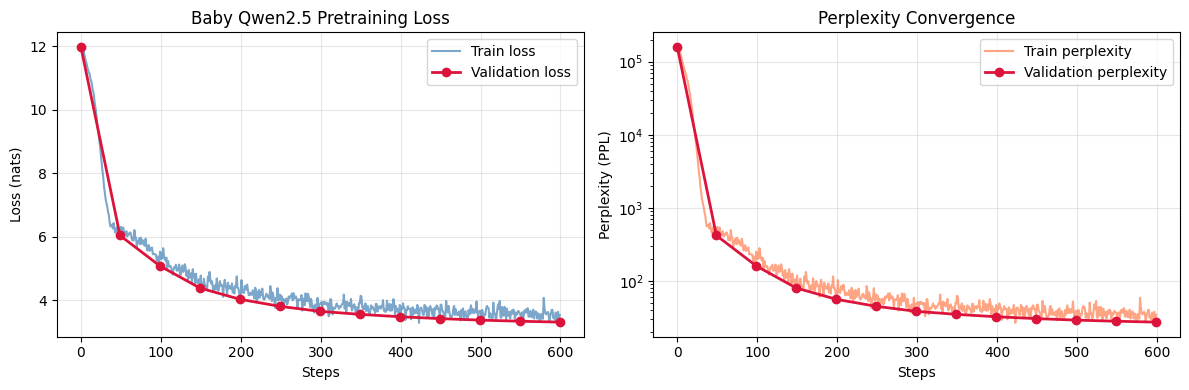

In [7]:
# Visualize Pretraining Curves
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history['step'], history['loss'], color='steelblue', lw=1.5, alpha=0.7, label='Train loss')
axes[0].plot(val_history['step'], val_history['loss'], color='crimson', lw=2, marker='o', label='Validation loss')
axes[0].set_title('Baby Qwen2.5 Pretraining Loss')
axes[0].set_xlabel('Steps')
axes[0].set_ylabel('Loss (nats)')
axes[0].grid(True, alpha=0.3)
axes[0].legend()

axes[1].plot(history['step'], history['ppl'], color='coral', lw=1.5, alpha=0.7, label='Train perplexity')
axes[1].plot(val_history['step'], val_history['ppl'], color='crimson', lw=2, marker='o', label='Validation perplexity')
axes[1].set_title('Perplexity Convergence')
axes[1].set_xlabel('Steps')
axes[1].set_ylabel('Perplexity (PPL)')
axes[1].set_yscale('log')
axes[1].grid(True, alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.show()

---
## 6. Generation & Decoding Benchmark

We generate with `model.generate()` from prompts that are **not** in the training data and compare three decoding strategies:

| Config | Settings | What it does |
|---|---|---|
| **Greedy** | `do_sample=False` | Always picks the single most likely token. Deterministic, so one sample per prompt. |
| **Nucleus (top-$p$)** | `temperature=0.7, top_p=0.9, repetition_penalty=1.1, do_sample=True` | Sharpens the distribution, samples only from the smallest token set covering 90% of probability, and down-weights tokens already generated. |
| **High temperature** | `temperature=1.4, do_sample=True` | Flattens the distribution, so low-probability tail tokens are sampled far more often. |

> **Note:** we pass `top_k=0` to both sampling configs. Otherwise Hugging Face silently applies its default `top_k=50`, which would truncate the tail and hide most of the high-temperature effect.

Besides reading the stories, each generation is scored with simple automatic measures:
- **distinct-2:** unique word bigrams / total bigrams. Low means repetitive.
- **rep-4:** fraction of word 4-grams that repeat an earlier 4-gram in the same story. High means a **repetition loop**.
- **loop:** some 4-gram occurs ≥3 times.
- **OOV%:** share of words that never appear in the training corpus. A proxy for **grammatical and lexical breakdown** (invented words, fragments).
- **keeps subject:** whether the prompt's subject ("Mia" / "dog") is mentioned again in the continuation. A crude **cohesion** check.
- **finished:** whether the model emitted `<|endoftext|>` before the token limit.

Sampling configs are scored over `N_SEEDS` seeds per prompt; the printed story is seed 0.

In [8]:
import re
from collections import Counter

DECODE_PROMPTS = [
    'Once upon a time, a little girl named Mia',
    'One day, a brave dog wanted to',
]
PROMPT_SUBJECT = {DECODE_PROMPTS[0]: 'mia', DECODE_PROMPTS[1]: 'dog'}
DECODING_CONFIGS = {
    'greedy':    dict(do_sample=False),
    'nucleus':   dict(do_sample=True, temperature=0.7, top_p=0.9, top_k=0, repetition_penalty=1.1),
    'high_temp': dict(do_sample=True, temperature=1.4, top_k=0),
}
MAX_NEW_TOKENS = 80
N_SEEDS = 3

# Every word that occurs in the training corpus (for the OOV / breakdown metric)
WORD_RE = re.compile(r"[a-z]+(?:'[a-z]+)?")
train_vocab = set(WORD_RE.findall(tokenizer.decode(train_tensor.flatten().tolist()).lower()))

@torch.no_grad()
def generate_story(m, prompt, cfg, seed=0, max_new_tokens=MAX_NEW_TOKENS):
    m.eval()
    torch.manual_seed(seed)
    ids = tokenizer.encode(prompt, return_tensors='pt').to(m.device)
    out = m.generate(ids, max_new_tokens=max_new_tokens,
                     pad_token_id=tokenizer.pad_token_id, eos_token_id=tokenizer.eos_token_id, **cfg)
    new_ids = out[0, ids.shape[1]:]
    return tokenizer.decode(new_ids, skip_special_tokens=True), len(new_ids)

def story_stats(continuation, n_new, prompt):
    words = WORD_RE.findall(continuation.lower())
    bi = [tuple(words[i:i + 2]) for i in range(len(words) - 1)]
    four = Counter(tuple(words[i:i + 4]) for i in range(len(words) - 3))
    n4 = max(1, len(words) - 3)
    return {
        'distinct2': len(set(bi)) / max(1, len(bi)),
        'rep4': (n4 - len(four)) / n4 if len(words) > 3 else 0.0,
        'loop': any(c >= 3 for c in four.values()),
        'oov': sum(w not in train_vocab for w in words) / max(1, len(words)),
        'keeps_subject': PROMPT_SUBJECT[prompt] in words,
        'finished': n_new < MAX_NEW_TOKENS,
    }

def decoding_benchmark(m, label, show=True):
    # Returns {config: averaged stats}; prints seed-0 stories if show=True
    rows = {}
    for cfg_name, cfg in DECODING_CONFIGS.items():
        seeds = [0] if not cfg.get('do_sample') else list(range(N_SEEDS))
        stats = []
        for prompt in DECODE_PROMPTS:
            for s in seeds:
                text, n_new = generate_story(m, prompt, cfg, seed=s)
                stats.append(story_stats(text, n_new, prompt))
                if show and s == 0:
                    print(f"[{label} | {cfg_name}] {prompt}{text}\n")
        rows[cfg_name] = {k: sum(float(st[k]) for st in stats) / len(stats) for k in stats[0]}
    return rows

def print_decoding_table(table):
    # table: {(model, config): stats}
    print(f"{'Model':<14} | {'Config':<9} | {'distinct-2':>10} | {'rep-4':>6} | {'loop':>5} | "
          f"{'OOV%':>5} | {'subject':>7} | {'finished':>8}")
    print('-' * 85)
    for (mname, cname), r in table.items():
        print(f"{mname:<14} | {cname:<9} | {r['distinct2']:>10.3f} | {r['rep4']:>6.3f} | {r['loop']:>5.0%} | "
              f"{r['oov']*100:>5.1f} | {r['keeps_subject']:>7.0%} | {r['finished']:>8.0%}")

print(f'Training vocabulary: {len(train_vocab):,} distinct words\n')
part1_rows = decoding_benchmark(model, 'baseline (Part 1)')
print_decoding_table({('baseline', c): r for c, r in part1_rows.items()})

Training vocabulary: 8,335 distinct words

[baseline (Part 1) | greedy] Once upon a time, a little girl named Mia was playing with her friends. She was very happy and wanted to play with her. She wanted to play with her mom, but she was too happy. She was happy and wanted to play with her. She said, "I'm sorry, I'm sorry, but I'm sorry. I'm sorry, I'm sorry. I'm sorry, I'm sorry. I'm sorry, I'm

[baseline (Part 1) | greedy] One day, a brave dog wanted to play with the tree. He saw a big, a big, and a big, and the bird. He was very happy and wanted to play with the tree. He was so happy and he had a big, he could not find it. He was so happy and he had a big hug. He had a big, but he was very happy. He had a big, but he was very

[baseline (Part 1) | nucleus] Once upon a time, a little girl named Mia and her mommy. She had a big, but she was so excited. She wanted to play with the ball, but she could find her favorite lunch. She saw that the toy came to her mom and said, "Yes, let's go 

---
## 7. Saving Checkpoint for LoRA Finetuning

We save our pretrained Baby Qwen checkpoint in standard Hugging Face format:
- `config.json`: Model architecture definition
- `model.safetensors` or `pytorch_model.bin`: Pretrained weight matrices
- `tokenizer_config.json` & `tokenizer.json`: Vocabulary and ChatML template

In **Week 5**, students load this exact folder with:
```python
from transformers import AutoModelForCausalLM, AutoTokenizer
from peft import LoraConfig, get_peft_model

model = AutoModelForCausalLM.from_pretrained('./baby_qwen_pretrained')
tokenizer = AutoTokenizer.from_pretrained('./baby_qwen_pretrained')
# Inject LoRA into q_proj and v_proj for Chat instruction tuning!
```


In [9]:
SAVE_DIR = 'baby_qwen_pretrained'
os.makedirs(SAVE_DIR, exist_ok=True)

# Save model weights and configuration
model.save_pretrained(SAVE_DIR)
tokenizer.save_pretrained(SAVE_DIR)
print(f"Checkpoint successfully saved to '{SAVE_DIR}/'")
print(f"Files created: {os.listdir(SAVE_DIR)}")

# Verify reloading works seamlessly
reloaded_model = Qwen2ForCausalLM.from_pretrained(SAVE_DIR).to(device)
reloaded_tokenizer = AutoTokenizer.from_pretrained(SAVE_DIR)
print(f'Verification: Reloaded Baby Qwen with {sum(p.numel() for p in reloaded_model.parameters()):,} parameters!')

# Persist to Google Drive so Week 5 notebooks can find it after this Colab runtime is wiped
import shutil, sys
DRIVE_ROOT = '/content/drive/MyDrive/ADS-NLP/BabyQwen'
if 'google.colab' in sys.modules:
    from google.colab import drive
    drive.mount('/content/drive')
    os.makedirs(DRIVE_ROOT, exist_ok=True)
    shutil.copytree(SAVE_DIR, os.path.join(DRIVE_ROOT, SAVE_DIR), dirs_exist_ok=True)
    print(f"Copied to Drive: {os.path.join(DRIVE_ROOT, SAVE_DIR)}/")
else:
    print('Not on Colab: checkpoint kept locally only.')

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Checkpoint successfully saved to 'baby_qwen_pretrained/'
Files created: ['config.json', 'tokenizer_config.json', 'chat_template.jinja', 'model.safetensors', 'generation_config.json', 'tokenizer.json']


Loading weights:   0%|          | 0/50 [00:00<?, ?it/s]

Verification: Reloaded Baby Qwen with 41,844,736 parameters!


---
## Summary & Key Takeaways

1. **Modern Architecture Primitives**: Baby Qwen2.5 implements Grouped-Query Attention (GQA), SwiGLU non-linearities, RMSNorm, and Rotary Position Embeddings (RoPE) inside a compact ~42M parameter budget. About 93% of those parameters are the vocabulary embedding table.
2. **Causal Pretraining Dynamics**: Cross-entropy next-token prediction drives loss down from $\ln(V) \approx 11.9$ (uniform guessing) as the model learns language statistics. Always track **validation** loss on held-out data. Train loss alone can't tell learning from memorization.
3. **Optimization Best Practices**: Linear warmup + cosine decay with AdamW and gradient clipping prevents divergence early in training.
4. **Direct Week 5 Handoff**: The saved checkpoint at `./baby_qwen_pretrained` is a Hugging Face model compatible with `peft` for LoRA fine-tuning in **Week 5**. It was pretrained on simple stories, so expect it to be a weak base model for instruction following. That is a useful contrast with large pretrained models.

---
# Part 2: Ablation Experiments (Options B & C)

The data domain stays fixed (same TinyStories train/val tensors as above). We change **one factor at a time** and measure validation loss, perplexity, and generation quality.

### Baseline reference (default notebook)
| | Value |
|---|---|
| Architecture | 4 layers, $d=256$, FFN $=768$, 8 Q heads / 2 KV heads (GQA), tied embeddings |
| Parameters | 41,844,736 total = 38,826,240 embedding ($151{,}665 \times 256$) + 3,018,240 transformer core |
| Budget | 600 steps × batch 8 × seq 256 ≈ 1.2M tokens |
| Result | Val loss ≈ 3.32, Val PPL ≈ 27.6 |

### Controlled-experiment setup
To make the comparison fair, every run below goes through the same `run_experiment` function:
- **Same initialization seed** and **same mini-batch order** (a dedicated `torch.Generator`), so for the first 600 steps all architectures see identical data.
- **Same optimizer recipe**: AdamW (lr $8\times10^{-4}$, $\beta=(0.9, 0.95)$, wd 0.01), 5% warmup, cosine decay to 10%, grad clip 1.0. The schedule is stretched to whatever `total_steps` the run uses.
- **Two evaluation signals** every 50 steps. **Val loss** uses the same 8 validation batches as Part 1, so numbers are comparable with the baseline's 27.6. **Train-probe loss** is computed in eval mode on a fixed set of 64 training sequences. This is a much less noisy estimate of train loss than the single-batch loss, which matters when we look at the train/val gap in Option C.
- At the end of each run we also score **the full validation split** for the headline table.

The baseline is re-run through the same function so all four runs share identical code.

In [10]:
import gc

# Reuse the data, tokenizer and optimizer hyperparameters from Part 1
EVAL_BATCHES = 8                       # same val subset as Part 1's evaluate()
train_probe = train_tensor[:EVAL_BATCHES * BATCH_SIZE]   # fixed slice of TRAINING data, scored in eval mode
GEN_PROMPTS = [
    'Once upon a time, a little girl named Mia',
    'One day, a brave dog wanted to',
    'Tom and his friend found a big box. Inside the box,',
]

def build_model(arch, seed=42):
    cfg = Qwen2Config(
        vocab_size=len(tokenizer),
        max_position_embeddings=1024,
        rope_theta=1000000.0,
        tie_word_embeddings=True,
        **arch,
    )
    torch.manual_seed(seed)
    return Qwen2ForCausalLM(cfg).to(device)

def count_params(m):
    emb = sum(p.numel() for p in m.model.embed_tokens.parameters())
    core = sum(p.numel() for p in m.model.layers.parameters())
    total = sum(p.numel() for p in m.parameters())
    return emb, core, total

@torch.no_grad()
def eval_loss(m, data, max_batches=None):
    # Token-weighted mean loss over (a prefix of) `data`
    m.eval()
    n = data.shape[0] if max_batches is None else min(data.shape[0], max_batches * BATCH_SIZE)
    tot, cnt = 0.0, 0
    for i in range(0, n, BATCH_SIZE):
        b = data[i : i + BATCH_SIZE].to(device)
        tot += m(input_ids=b, labels=b).loss.item() * b.shape[0]
        cnt += b.shape[0]
    m.train()
    return tot / cnt

@torch.no_grad()
def sample_text(m, prompts, seed=0, max_new_tokens=60):
    m.eval()
    outs = []
    for p in prompts:
        torch.manual_seed(seed)   # same sampling noise for every model -> fairer side-by-side
        ids = tokenizer.encode(p, return_tensors='pt').to(device)
        g = m.generate(
            ids, max_new_tokens=max_new_tokens, temperature=0.7, top_k=50, top_p=0.9,
            repetition_penalty=1.1, do_sample=True,
            pad_token_id=tokenizer.pad_token_id, eos_token_id=tokenizer.eos_token_id,
        )
        outs.append(tokenizer.decode(g[0], skip_special_tokens=True))
    m.train()
    return outs

def run_experiment(name, arch, total_steps=600, lr_max=LEARNING_RATE, seed=42, eval_every=50):
    m = build_model(arch, seed)
    emb, core, total = count_params(m)
    print(f"\n=== {name} === layers={arch['num_hidden_layers']} d={arch['hidden_size']} "
          f"ffn={arch['intermediate_size']} heads={arch['num_attention_heads']}/{arch['num_key_value_heads']}")
    print(f"params: embedding {emb:,} | core {core:,} | total {total:,} | steps {total_steps}")

    opt = torch.optim.AdamW(m.parameters(), lr=lr_max, betas=(0.9, 0.95), weight_decay=WEIGHT_DECAY)
    warmup = int(0.05 * total_steps)
    def lr_at(step):
        if step < warmup:
            return lr_max * (step + 1) / warmup
        progress = (step - warmup) / max(1, total_steps - warmup)
        return 0.1 * lr_max + 0.5 * (1.0 + math.cos(math.pi * progress)) * (0.9 * lr_max)

    batch_gen = torch.Generator().manual_seed(seed)   # identical batch order across runs
    log = {'step': [], 'train_loss': [], 'eval_step': [], 'val_loss': [], 'train_probe_loss': []}

    print(f"{'Step':>5} | {'Train(batch)':>12} | {'Train(probe)':>12} | {'Val Loss':>8} | {'Val PPL':>8} | {'Gap':>7}")
    print('-' * 68)
    m.train()
    train_time = 0.0
    for step in range(total_steps):
        t0 = time.time()
        for g in opt.param_groups:
            g['lr'] = lr_at(step)
        idx = torch.randint(0, train_tensor.shape[0], (BATCH_SIZE,), generator=batch_gen)
        batch = train_tensor[idx].to(device)
        opt.zero_grad()
        loss = m(input_ids=batch, labels=batch).loss
        loss.backward()
        torch.nn.utils.clip_grad_norm_(m.parameters(), max_norm=1.0)
        opt.step()
        cur = loss.item()   # syncs device
        train_time += time.time() - t0
        log['step'].append(step)
        log['train_loss'].append(cur)

        if (step + 1) % eval_every == 0 or step == 0:
            v = eval_loss(m, val_tensor, EVAL_BATCHES)
            tp = eval_loss(m, train_probe)
            log['eval_step'].append(step + 1)
            log['val_loss'].append(v)
            log['train_probe_loss'].append(tp)
            print(f"{step + 1:>5} | {cur:>12.4f} | {tp:>12.4f} | {v:>8.4f} | {math.exp(min(v, 20)):>8.2f} | {v - tp:>+7.4f}")

    full_val = eval_loss(m, val_tensor)          # entire held-out split
    samples = sample_text(m, GEN_PROMPTS)
    tokens = total_steps * BATCH_SIZE * SEQ_LEN
    res = {
        'name': name, 'arch': arch, 'steps': total_steps,
        'emb_params': emb, 'core_params': core, 'total_params': total,
        'tokens': tokens, 'epochs': tokens / train_tensor.numel(),
        'train_time_s': train_time, 'tok_per_s': tokens / train_time,
        'final_val_loss': log['val_loss'][-1], 'final_val_ppl': math.exp(log['val_loss'][-1]),
        'final_train_probe_loss': log['train_probe_loss'][-1],
        'full_val_loss': full_val, 'full_val_ppl': math.exp(full_val),
        'log': log, 'samples': samples,
    }
    print(f"-> val loss {res['final_val_loss']:.4f} (PPL {res['final_val_ppl']:.2f}) | "
          f"full-val PPL {res['full_val_ppl']:.2f} | {res['epochs']:.2f} epochs | "
          f"{train_time:.0f}s ({res['tok_per_s']:,.0f} tok/s)")

    res['model'] = m.cpu()   # keep the trained weights for the decoding benchmark (Section 12)
    del m, opt
    gc.collect()
    if device == 'cuda':
        torch.cuda.empty_cache()
    elif device == 'mps':
        torch.mps.empty_cache()
    return res

RESULTS = {}

---
## 8. Re-run the Baseline under the Controlled Harness

Same architecture as Part 1 (4L, $d=256$, FFN 768, 8/2 heads), 600 steps. This should land close to the Part 1 numbers (val PPL ≈ 27–28). Small differences come from the different batch-sampling generator.

In [11]:
ARCHS = {
    'baseline': dict(num_hidden_layers=4, hidden_size=256, intermediate_size=768,
                     num_attention_heads=8, num_key_value_heads=2),
}
RESULTS['baseline'] = run_experiment('Baseline (4L x 256)', ARCHS['baseline'], total_steps=600)


=== Baseline (4L x 256) === layers=4 d=256 ffn=768 heads=8/2
params: embedding 38,826,240 | core 3,018,240 | total 41,844,736 | steps 600
 Step | Train(batch) | Train(probe) | Val Loss |  Val PPL |     Gap
--------------------------------------------------------------------
    1 |      12.0223 |      11.9890 |  11.9781 | 159230.03 | -0.0109
   50 |       6.1904 |       6.2567 |   6.0889 |   440.94 | -0.1678
  100 |       5.2201 |       5.3271 |   5.0359 |   153.84 | -0.2911
  150 |       4.6058 |       4.6509 |   4.3618 |    78.40 | -0.2890
  200 |       4.3146 |       4.3032 |   4.0081 |    55.04 | -0.2951
  250 |       4.1937 |       4.0777 |   3.8083 |    45.07 | -0.2693
  300 |       3.9037 |       3.9002 |   3.6439 |    38.24 | -0.2563
  350 |       3.6980 |       3.7751 |   3.5331 |    34.23 | -0.2420
  400 |       3.9785 |       3.6994 |   3.4685 |    32.09 | -0.2309
  450 |       3.6228 |       3.6198 |   3.4030 |    30.05 | -0.2168
  500 |       3.5674 |       3.5598 |   3.3

---
## 9. Option B: Depth vs. Width Allocation

We grow the transformer core by about 2× in two different ways and compare them at the **same 1.2M-token budget**:

| Variant | Layers | $d$ | FFN | Q / KV heads | head dim | Core params | Embedding params | Total |
|---|---|---|---|---|---|---|---|---|
| Baseline | 4 | 256 | 768 | 8 / 2 | 32 | 3.02M | 38.83M | 41.84M |
| **Deeper** | **6** | 256 | 1024 | 8 / 2 | 32 | **5.71M** | 38.83M | 44.53M |
| **Wider** | 4 | **384** | 1024 | **12 / 3** | 32 | **6.20M** | 58.24M | 64.44M |

Design notes:
- Both variants keep **head dim = 32** and the **4:1 GQA ratio**, so the only change is depth versus width.
- FFN 1024 is $\frac{8}{3}d$ for $d=384$. Using it for the deeper model too keeps the two **core** budgets within ~9% of each other (5.71M vs 6.20M).
- **Caveat:** width also widens the embedding table. Wider has +19.4M embedding parameters, which is a large share of the total. Embedding rows are lookups, and only the rows for tokens TinyStories actually uses get meaningful gradient, so the fair comparison is on **core (non-embedding) parameters**. This follows Kaplan et al. (2020), who define $N$ excluding embeddings. The wider model also pays more compute in the 151k-way output projection ($384 \times 151{,}665$ per token), which shows up in tokens/sec.

**Hypothesis.** Kaplan et al. found that at a fixed non-embedding parameter count, loss depends only weakly on the depth/width aspect ratio. At this tiny scale and short budget, depth tends to help a bit, because more layers compose more sequential operations (e.g. tracking a character across sentences). Wide-and-shallow models tend to optimize slightly faster early on. Very deep, narrow models also train more slowly in few steps. We test which effect wins here.

> To try other shapes, edit the dicts below. The parameter table prints automatically.

In [12]:
ARCHS['deeper'] = dict(num_hidden_layers=6, hidden_size=256, intermediate_size=1024,
                       num_attention_heads=8, num_key_value_heads=2)
ARCHS['wider'] = dict(num_hidden_layers=4, hidden_size=384, intermediate_size=1024,
                      num_attention_heads=12, num_key_value_heads=3)

RESULTS['deeper'] = run_experiment('Option B: Deeper (6L x 256)', ARCHS['deeper'], total_steps=600)
RESULTS['wider'] = run_experiment('Option B: Wider (4L x 384)', ARCHS['wider'], total_steps=600)


=== Option B: Deeper (6L x 256) === layers=6 d=256 ffn=1024 heads=8/2
params: embedding 38,826,240 | core 5,707,008 | total 44,533,504 | steps 600
 Step | Train(batch) | Train(probe) | Val Loss |  Val PPL |     Gap
--------------------------------------------------------------------
    1 |      11.9690 |      11.9555 |  11.9460 | 154203.14 | -0.0094
   50 |       6.1904 |       6.2408 |   6.0751 |   434.90 | -0.1657
  100 |       5.1379 |       5.2605 |   4.9719 |   144.31 | -0.2886
  150 |       4.5234 |       4.5766 |   4.2954 |    73.36 | -0.2812
  200 |       4.2683 |       4.2627 |   3.9694 |    52.95 | -0.2933
  250 |       4.1529 |       4.0415 |   3.7615 |    43.01 | -0.2800
  300 |       3.8796 |       3.8649 |   3.6071 |    36.86 | -0.2579
  350 |       3.6938 |       3.7474 |   3.5035 |    33.23 | -0.2439
  400 |       3.9366 |       3.6682 |   3.4374 |    31.11 | -0.2308
  450 |       3.5847 |       3.5848 |   3.3655 |    28.95 | -0.2194
  500 |       3.5221 |       3.520

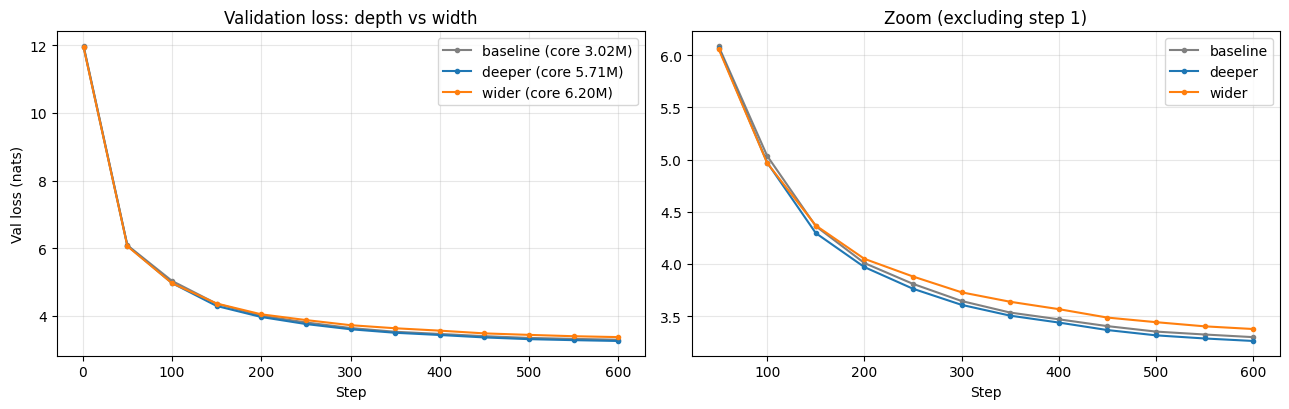

Run                            |    Core |   Total | Val Loss | Val PPL | Full PPL |     Gap |    Tok/s
-------------------------------------------------------------------------------------------------------
Baseline (4L x 256)            |   3.02M |  41.84M |   3.2974 |   27.04 |    29.23 | -0.2052 |   17,536
Option B: Deeper (6L x 256)    |   5.71M |  44.53M |   3.2607 |   26.07 |    28.23 | -0.2025 |   16,194
Option B: Wider (4L x 384)     |   6.20M |  64.44M |   3.3753 |   29.23 |    31.85 | -0.2129 |   12,371

At 1.2M tokens, DEEPER wins on full-validation PPL: deeper 28.23 vs wider 31.85 (baseline 29.23).
  deeper : dLoss vs baseline = -0.0349 nats, per extra core-M param = -0.0130, wall-clock 76s vs 70s
  wider  : dLoss vs baseline = +0.0857 nats, per extra core-M param = +0.0270, wall-clock 99s vs 70s


In [13]:
# Option B: curves + summary
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
colors = {'baseline': 'gray', 'deeper': 'tab:blue', 'wider': 'tab:orange'}
for k in ['baseline', 'deeper', 'wider']:
    r = RESULTS[k]; lg = r['log']
    axes[0].plot(lg['eval_step'], lg['val_loss'], marker='o', ms=3, color=colors[k],
                 label=f"{k} (core {r['core_params']/1e6:.2f}M)")
    axes[1].plot(lg['eval_step'][1:], lg['val_loss'][1:], marker='o', ms=3, color=colors[k], label=k)
axes[0].set_title('Validation loss: depth vs width'); axes[0].set_xlabel('Step'); axes[0].set_ylabel('Val loss (nats)')
axes[1].set_title('Zoom (excluding step 1)'); axes[1].set_xlabel('Step')
for ax in axes: ax.grid(alpha=0.3); ax.legend()
plt.tight_layout(); plt.show()

def summary_row(r):
    return (f"{r['name']:<30} | {r['core_params']/1e6:>6.2f}M | {r['total_params']/1e6:>6.2f}M | "
            f"{r['final_val_loss']:>8.4f} | {r['final_val_ppl']:>7.2f} | {r['full_val_ppl']:>8.2f} | "
            f"{r['final_val_loss'] - r['final_train_probe_loss']:>+7.4f} | {r['tok_per_s']:>8,.0f}")
hdr = (f"{'Run':<30} | {'Core':>7} | {'Total':>7} | {'Val Loss':>8} | {'Val PPL':>7} | "
       f"{'Full PPL':>8} | {'Gap':>7} | {'Tok/s':>8}")
print(hdr); print('-' * len(hdr))
for k in ['baseline', 'deeper', 'wider']:
    print(summary_row(RESULTS[k]))

b, d, w = RESULTS['baseline'], RESULTS['deeper'], RESULTS['wider']
winner = 'DEEPER' if d['full_val_loss'] < w['full_val_loss'] else 'WIDER'
print(f"\nAt 1.2M tokens, {winner} wins on full-validation PPL: "
      f"deeper {d['full_val_ppl']:.2f} vs wider {w['full_val_ppl']:.2f} (baseline {b['full_val_ppl']:.2f}).")
for k in ['deeper', 'wider']:
    r = RESULTS[k]
    print(f"  {k:<7}: dLoss vs baseline = {r['full_val_loss'] - b['full_val_loss']:+.4f} nats, "
          f"per extra core-M param = {(r['full_val_loss'] - b['full_val_loss']) / ((r['core_params'] - b['core_params'])/1e6):+.4f}, "
          f"wall-clock {r['train_time_s']:.0f}s vs {b['train_time_s']:.0f}s")

In [14]:
# Option B: generation quality side-by-side (same prompts, same sampling seed)
for i, p in enumerate(GEN_PROMPTS):
    print('=' * 90)
    print('PROMPT:', p)
    for k in ['baseline', 'deeper', 'wider']:
        print(f"\n[{k}] {RESULTS[k]['samples'][i]}")
print('=' * 90)

PROMPT: Once upon a time, a little girl named Mia

[baseline] Once upon a time, a little girl named Mia. Lily loved to play with her toys and play with her mom. One day, Lily's mom went to the park. She looked at the park and saw her favorite ball. She said, "No, Lily! I love you for my way!" she says, "Let's go to the

[deeper] Once upon a time, a little girl named Mia. She was very happy to play with her toys and play with her friends. They were so excited and went to the park. One day, they saw a big dog in the park. It was a big and a little boy who wanted to do it.

So, Lily's mom and dad went

[wider] Once upon a time, a little girl named Mia. She was very excited to play with her friend, so she went on a special doll and saw a big tree on the ground.

One day, she saw a little girl named Lily. She felt happy that she could make him look for the kitchen. She was very sad and he could help her
PROMPT: One day, a brave dog wanted to

[baseline] One day, a brave dog wanted to explor

### Option B: Results

**Question:** with 1.2M training tokens, is it better to go deeper or wider?

**Answer: deeper.** Deeper beats the baseline a little. Wider is worse than the baseline, even with 2× the core params.

| Run | Core | Total | Val PPL | Full-val PPL | Change vs baseline | Tok/s | Time |
|---|---|---|---|---|---|---|---|
| Baseline (4L × 256) | 3.02M | 41.84M | 27.04 | **29.23** | — | 17,536 | 70s |
| Deeper (6L × 256) | 5.71M | 44.53M | 26.07 | **28.23** | −0.035 nats (−3.4%) | 16,194 | 76s |
| Wider (4L × 384) | 6.20M | 64.44M | 29.23 | **31.85** | +0.086 nats (+9.0%) | 12,371 | 99s |

**Is the difference real?** The Part 1 baseline and the re-run differ by about 0.02 nats, so that is our rough noise level.
- Wider's loss (+0.086) is about 4× the noise, so it is real.
- Deeper's gain (−0.035) is only about 2× the noise. But deeper is ahead at all 12 checkpoints, so it is likely real, just small. More seeds would confirm it.

**Learning curves**
- Wider is best at steps 50–100, then falls behind from step 150 and never recovers.
- Deeper pulls ahead early and keeps a steady ~0.035-nat lead.

**Why wider loses** (likely reasons, not tested)
1. A wider model also has a bigger embedding table: +19.4M params (151,665 × 384), all of which have to be learned from the same 1.2M tokens.
2. The learning rate (8e-4) was picked for d=256. Wider models usually need a lower LR.
3. It is 29% slower, mostly because of the larger output layer.

**Generation:** the three models look about the same.
- All write mostly grammatical sentences.
- All forget the prompt's name ("Mia" becomes "Lily").
- Deeper reads slightly smoother; wider sometimes writes "The end." and keeps going.
- (`â€œ` in one sample is a broken quote character copied from the training data, not a model bug.)

**Takeaway:** in a small model where the vocabulary takes most of the parameters, extra parameters should go into more layers, not a bigger hidden size.

---
## 10. Option C: Compute & Token Scaling (Chinchilla Frontier)

Same baseline architecture, **double the training duration**:

```python
TOTAL_STEPS = 1200   # ~2.4M tokens, ~1.9 epochs over the 6,000 stories
```

Warmup (5%) and cosine decay are stretched to 1200 steps, so this is a properly tuned longer run. It does not continue the 600-step run.

**Where we are on the Chinchilla frontier.** Hoffmann et al. (2022) put the compute-optimal ratio at ~20 tokens per parameter.
- Counting the **core** (3.0M), the optimal budget is ≈ 60M tokens. We train on 1.2M → 2.4M, which is **2–4% of compute-optimal**.
- Counting **all** 41.8M parameters, the optimum is ≈ 840M tokens.

Either way the model is heavily **under-trained**. Loss should keep falling with more tokens.

**The catch: the extra tokens are repeats.** The corpus is only ~1.3M tokens, so step 1200 means each story has been seen about twice. Muennighoff et al. (2023, *Scaling Data-Constrained Language Models*) found that up to ~4 epochs of repeated data is nearly as valuable as fresh data, with returns decaying fast after that. Prediction:
- Val loss keeps decreasing, but the 600→1200 improvement is **smaller** than 300→600 (diminishing returns: loss is roughly a power law in tokens).
- The train/val gap opens **slightly** in the second epoch, as the model starts memorizing specific stories, but stays small. Clear overfitting (val loss rising while train loss falls) would need many more epochs.

In [15]:
RESULTS['baseline_1200'] = run_experiment('Option C: Baseline x 1200 steps', ARCHS['baseline'], total_steps=1200)


=== Option C: Baseline x 1200 steps === layers=4 d=256 ffn=768 heads=8/2
params: embedding 38,826,240 | core 3,018,240 | total 41,844,736 | steps 1200
 Step | Train(batch) | Train(probe) | Val Loss |  Val PPL |     Gap
--------------------------------------------------------------------
    1 |      12.0223 |      12.0045 |  11.9954 | 162013.99 | -0.0091
   50 |       6.5116 |       6.4761 |   6.3452 |   569.72 | -0.1310
  100 |       5.2344 |       5.3360 |   5.0398 |   154.44 | -0.2962
  150 |       4.5332 |       4.5785 |   4.2759 |    71.94 | -0.3026
  200 |       4.2097 |       4.2113 |   3.9103 |    49.91 | -0.3010
  250 |       4.1236 |       3.9770 |   3.7118 |    40.93 | -0.2652
  300 |       3.8403 |       3.8015 |   3.5545 |    34.97 | -0.2470
  350 |       3.6110 |       3.6835 |   3.4402 |    31.19 | -0.2433
  400 |       3.8503 |       3.5905 |   3.3661 |    28.97 | -0.2244
  450 |       3.4990 |       3.4727 |   3.2683 |    26.27 | -0.2044
  500 |       3.4050 |       3

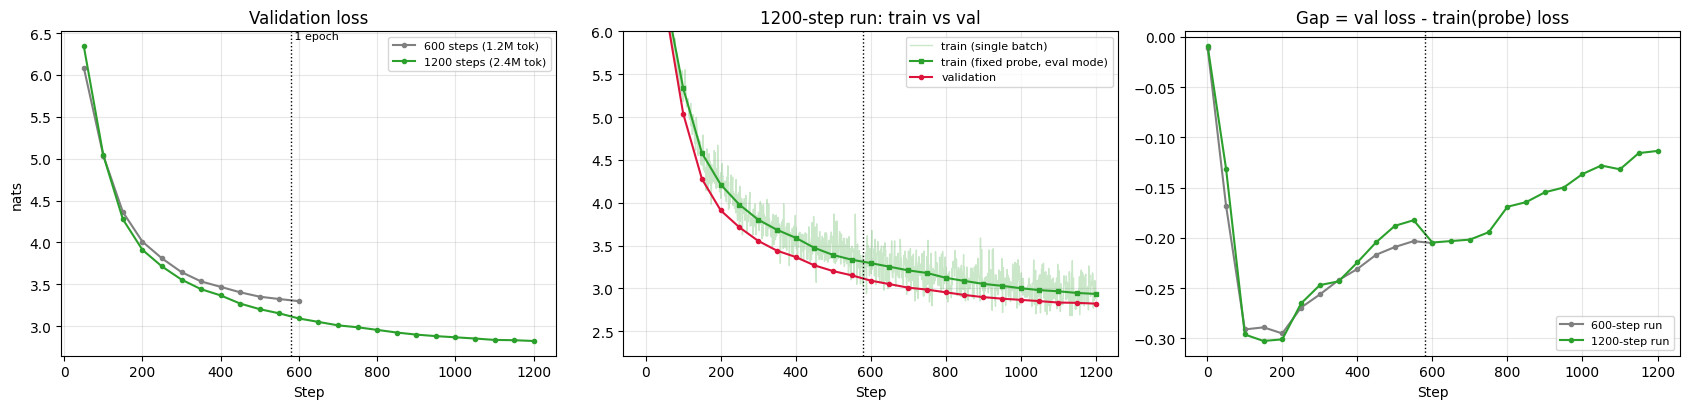

Run                            |    Core |   Total | Val Loss | Val PPL | Full PPL |     Gap |    Tok/s
-------------------------------------------------------------------------------------------------------
Baseline (4L x 256)            |   3.02M |  41.84M |   3.2974 |   27.04 |    29.23 | -0.2052 |   17,536
Option C: Baseline x 1200 steps |   3.02M |  41.84M |   2.8218 |   16.81 |    18.28 | -0.1134 |   17,536

Val-loss drop per 200-step window (1200-step run):
  steps  200 ->  400: +0.5442 nats   (val PPL  49.91 ->  28.97)
  steps  400 ->  600: +0.2756 nats   (val PPL  28.97 ->  21.99)
  steps  600 ->  800: +0.1363 nats   (val PPL  21.99 ->  19.19)
  steps  800 -> 1000: +0.0887 nats   (val PPL  19.19 ->  17.56)
  steps 1000 -> 1200: +0.0438 nats   (val PPL  17.56 ->  16.81)

Doubling tokens: full-val loss 3.3752 -> 2.9057 (+0.4695 nats, PPL 29.23 -> 18.28, 37.5% lower)
Gap at end: 600-step run -0.2052 | 1200-step run -0.1134 nats
No overfitting in the classic sense: val loss is sti

In [16]:
# Option C: learning curves, train/val gap, and diminishing returns
r6, r12 = RESULTS['baseline'], RESULTS['baseline_1200']
l6, l12 = r6['log'], r12['log']
epoch_steps = train_tensor.numel() / (BATCH_SIZE * SEQ_LEN)   # steps per epoch

fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))

# (a) val loss: 600 vs 1200 steps
axes[0].plot(l6['eval_step'][1:], l6['val_loss'][1:], 'o-', ms=3, color='gray', label='600 steps (1.2M tok)')
axes[0].plot(l12['eval_step'][1:], l12['val_loss'][1:], 'o-', ms=3, color='tab:green', label='1200 steps (2.4M tok)')
axes[0].set_title('Validation loss'); axes[0].set_xlabel('Step'); axes[0].set_ylabel('nats')

# (b) train-probe vs val for the 1200-step run
axes[1].plot(l12['step'], l12['train_loss'], color='tab:green', alpha=0.25, lw=1, label='train (single batch)')
axes[1].plot(l12['eval_step'], l12['train_probe_loss'], 's-', ms=3, color='tab:green', label='train (fixed probe, eval mode)')
axes[1].plot(l12['eval_step'], l12['val_loss'], 'o-', ms=3, color='crimson', label='validation')
axes[1].set_ylim(top=min(6, max(l12['val_loss'][1:]) + 0.5))
axes[1].set_title('1200-step run: train vs val'); axes[1].set_xlabel('Step')

# (c) generalization gap over time
gap12 = [v - t for v, t in zip(l12['val_loss'], l12['train_probe_loss'])]
gap6 = [v - t for v, t in zip(l6['val_loss'], l6['train_probe_loss'])]
axes[2].plot(l6['eval_step'], gap6, 'o-', ms=3, color='gray', label='600-step run')
axes[2].plot(l12['eval_step'], gap12, 'o-', ms=3, color='tab:green', label='1200-step run')
axes[2].axhline(0, color='k', lw=0.8)
axes[2].set_title('Gap = val loss - train(probe) loss'); axes[2].set_xlabel('Step')

for ax in axes:
    ax.axvline(epoch_steps, color='k', ls=':', lw=1)
    ax.grid(alpha=0.3); ax.legend(fontsize=8)
axes[0].text(epoch_steps, axes[0].get_ylim()[1], ' 1 epoch', va='top', fontsize=8)
plt.tight_layout(); plt.show()

print(hdr); print('-' * len(hdr))
for k in ['baseline', 'baseline_1200']:
    print(summary_row(RESULTS[k]))

# Diminishing returns: val-loss improvement per 200-step window of the 1200-step run
print('\nVal-loss drop per 200-step window (1200-step run):')
ev = dict(zip(l12['eval_step'], l12['val_loss']))
for a, b_ in zip(range(200, 1200, 200), range(400, 1201, 200)):
    print(f"  steps {a:>4} -> {b_:>4}: {ev[a] - ev[b_]:+.4f} nats   (val PPL {math.exp(ev[a]):6.2f} -> {math.exp(ev[b_]):6.2f})")

d_loss = r6['full_val_loss'] - r12['full_val_loss']
print(f"\nDoubling tokens: full-val loss {r6['full_val_loss']:.4f} -> {r12['full_val_loss']:.4f} "
      f"({d_loss:+.4f} nats, PPL {r6['full_val_ppl']:.2f} -> {r12['full_val_ppl']:.2f}, "
      f"{(1 - r12['full_val_ppl']/r6['full_val_ppl'])*100:.1f}% lower)")
print(f"Gap at end: 600-step run {gap6[-1]:+.4f} | 1200-step run {gap12[-1]:+.4f} nats")
min_i = min(range(len(l12['val_loss'])), key=lambda i: l12['val_loss'][i])
if l12['eval_step'][min_i] < l12['eval_step'][-1] and l12['val_loss'][-1] - l12['val_loss'][min_i] > 0.01:
    print(f"OVERFITTING: val loss bottomed at step {l12['eval_step'][min_i]} and rose afterwards.")
else:
    print("No overfitting in the classic sense: val loss is still at (or within noise of) its minimum at the final step.")

In [17]:
# Option C: generation quality, 600 vs 1200 steps
for i, p in enumerate(GEN_PROMPTS):
    print('=' * 90)
    print('PROMPT:', p)
    for k in ['baseline', 'baseline_1200']:
        print(f"\n[{k}] {RESULTS[k]['samples'][i]}")
print('=' * 90)

PROMPT: Once upon a time, a little girl named Mia

[baseline] Once upon a time, a little girl named Mia. Lily loved to play with her toys and play with her mom. One day, Lily's mom went to the park. She looked at the park and saw her favorite ball. She said, "No, Lily! I love you for my way!" she says, "Let's go to the

[baseline_1200] Once upon a time, a little girl named Mia was walking through the forest. She saw a big, beautiful rock and wanted to see what it was inside.

But when she got there, she saw something shiny in the air. It had a big eyes and a big, yellow flower. Sue wanted to help, so she asked her mom if she
PROMPT: One day, a brave dog wanted to

[baseline] One day, a brave dog wanted to explore the park. She knew she was too fast, so she went down with her family and saw the big tree. The boy looked at the boy and saw a little girl. She said, "No, Lily! I love you for my way!" 

So, Jane and the bird saw the

[baseline_1200] One day, a brave dog wanted to explore the

### Option C: Results

| Run | Tokens | Epochs | Val PPL | Full-val PPL | Gap (val − train) | Time |
|---|---|---|---|---|---|---|
| 600 steps | 1.23M | 1.04 | 27.04 | **29.23** | −0.205 | 70s |
| 1200 steps | 2.46M | 2.07 | 16.81 | **18.28** | −0.113 | 140s |

Doubling the tokens cut val loss by **0.47 nats** (PPL 29.2 → 18.3, **−37.5%**). That is 13× more than going deeper gained.

**Q1: Does val loss keep falling, or does it slow down?** Both. It drops at every checkpoint, with no plateau, but each 200 steps gives about half the gain of the previous 200:

| Steps | 200→400 | 400→600 | 600→800 | 800→1000 | 1000→1200 |
|---|---|---|---|---|---|
| Val loss drop | 0.544 | 0.276 | 0.136 | 0.089 | 0.044 |

Part of the slowdown is natural (loss follows a power law). Part is the learning rate decaying at the end of the cosine schedule. Val loss was still falling at step 1200, so more training would still help.

**Side finding: the LR schedule matters.** Both runs saw exactly the same data for the first 600 steps. At step 600 the 1200-step run (LR still high) had val loss **3.091**, while the 600-step run (LR already decayed) ended at **3.297**. So the 600-step baseline decays its LR too early, and part of Option C's gain comes from the longer schedule, not only from more data.

**Q2: Does the train/val gap widen?** Yes, a little, but there is no overfitting.
- Val loss is *lower* than train loss in every run, by ~0.2–0.3 nats. This shows up by step 100, before any memorization, so it comes from the data: the validation stories seem easier. So we look at how the gap *changes*, not its sign.
- The gap moves toward train: −0.30 (step 200) → −0.205 (step 600) → −0.113 (step 1200). In the second epoch, train loss improves faster than val loss: 1.26× → 1.37× → 1.53× per 200 steps. The model is starting to memorize stories it has seen twice.
- **No overfitting:** val loss never went up and is lowest at the last step. This matches Muennighoff et al. (2023): about 2–4 epochs of repeated data is almost as good as new data.
- Rough guess (not measured): val loss might start rising after about 4+ epochs (~2,500 steps).

**Generation:** this is the biggest quality jump of any experiment.
- *1200 steps:* "Mia was walking through the forest. She saw a big, beautiful rock and wanted to see what it was inside. But when she got there, she saw something shiny…" It also completes the box prompt sensibly: "there was a big, red ball".
- *600 steps:* swaps "Mia" for "Lily", writes broken dialogue ("I love you for my way!"), and puts "a big hug" inside the box.
- Still wrong at 1200: names drift (Mia → Sue), and some grammar slips ("It had a big eyes").

---
## 11. All Runs at a Glance

Run                            |    Core |   Total | Val Loss | Val PPL | Full PPL |     Gap |    Tok/s | Tokens | Epochs
---------------------------------------------------------------------------------------------------------------------------
Baseline (4L x 256)            |   3.02M |  41.84M |   3.2974 |   27.04 |    29.23 | -0.2052 |   17,536 |  1.23M |   1.04
Option B: Deeper (6L x 256)    |   5.71M |  44.53M |   3.2607 |   26.07 |    28.23 | -0.2025 |   16,194 |  1.23M |   1.04
Option B: Wider (4L x 384)     |   6.20M |  64.44M |   3.3753 |   29.23 |    31.85 | -0.2129 |   12,371 |  1.23M |   1.04
Option C: Baseline x 1200 steps |   3.02M |  41.84M |   2.8218 |   16.81 |    18.28 | -0.1134 |   17,536 |  2.46M |   2.07


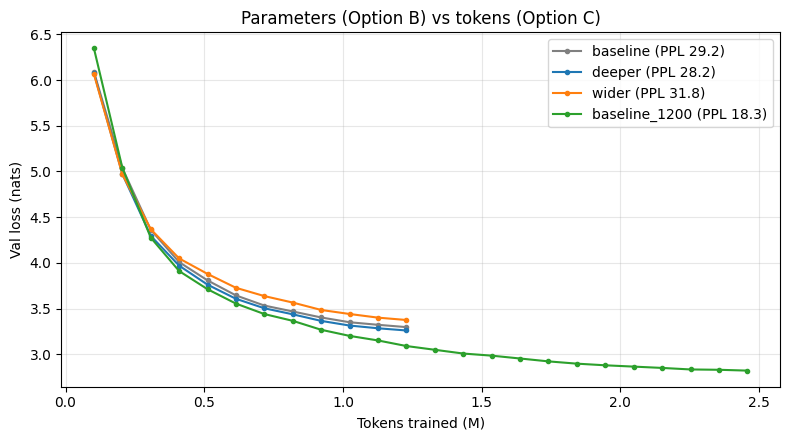


Best full-val PPL: baseline_1200 (18.28)
Ask: at this budget, is ~2x core params (B) or 2x tokens (C) the better use of extra compute?


In [18]:
order = ['baseline', 'deeper', 'wider', 'baseline_1200']
print(hdr + f" | {'Tokens':>6} | {'Epochs':>6}")
print('-' * (len(hdr) + 20))
for k in order:
    r = RESULTS[k]
    print(summary_row(r) + f" | {r['tokens']/1e6:>5.2f}M | {r['epochs']:>6.2f}")

fig, ax = plt.subplots(figsize=(8, 4.5))
cols = {'baseline': 'gray', 'deeper': 'tab:blue', 'wider': 'tab:orange', 'baseline_1200': 'tab:green'}
for k in order:
    lg = RESULTS[k]['log']
    ax.plot([s * BATCH_SIZE * SEQ_LEN / 1e6 for s in lg['eval_step'][1:]], lg['val_loss'][1:],
            'o-', ms=3, color=cols[k], label=f"{k} (PPL {RESULTS[k]['full_val_ppl']:.1f})")
ax.set_xlabel('Tokens trained (M)'); ax.set_ylabel('Val loss (nats)')
ax.set_title('Parameters (Option B) vs tokens (Option C)')
ax.grid(alpha=0.3); ax.legend()
plt.tight_layout(); plt.show()

best = min(order, key=lambda k: RESULTS[k]['full_val_loss'])
print(f"\nBest full-val PPL: {best} ({RESULTS[best]['full_val_ppl']:.2f})")
print("Ask: at this budget, is ~2x core params (B) or 2x tokens (C) the better use of extra compute?")

### Discussion

**1. Depth vs width:** depth won.
- Full-val PPL: deeper 28.23, baseline 29.23, wider 31.85.
- Deeper's gain is small (about 2× noise) but consistent. Wider is clearly worse.
- Generated stories look about the same for all three.
- Reason: making the model wider also makes the 151k-word embedding and output layer bigger (+19.4M params, 29% slower), and the LR was tuned for d=256. Adding layers only grows the core.

**2. More parameters vs more tokens:** tokens won by far.
- 2× tokens: −0.47 nats. 2× core params: −0.035 (deeper) or +0.086 (wider).
- Caveat: Option B did not really double compute. Most of the work is in the output layer, so B only took 9–41% more time (76s / 99s vs 70s), while C took 2× (140s). Per extra second, deeper and 2× tokens give similar gains. But deeper's gain is capped because there is not enough data, while the token side has much more room.
- This matches Chinchilla. We train on ~0.4 tokens per core parameter, against the ~20 that is compute-optimal, so the model needs more data far more than more parameters.
- Part of C's gain comes from its longer LR schedule (see Option C).

**3. Overfitting:** not yet.
- The train/val gap shrank from −0.205 to −0.113 in the second epoch, so the model is starting to memorize.
- But val loss was still going down at step 1200.
- Guess: overfitting would start after ~4 epochs. The easy fix is more stories (`N_TRAIN_STORIES`), not more epochs.

**Next experiments:**
- (a) more seeds for Option B;
- (b) deeper model at 1200 steps;
- (c) wider model with a lower LR (e.g. 5e-4);
- (d) `N_TRAIN_STORIES = 12_000` at 1200 steps, to separate "more data" from "repeated data".

---
## 12. Decoding Benchmark across Baseline and Ablated Models

The same three decoding configs (greedy / nucleus / high temperature) and the same two prompts as Cell 14 are applied to every model trained in Part 2:

| Model | What changed |
|---|---|
| `baseline` | 4L × 256, 600 steps |
| `deeper` | 6L × 256, 600 steps (Option B) |
| `wider` | 4L × 384, 600 steps (Option B) |
| `baseline_1200` | 4L × 256, 1200 steps (Option C) |

Each model is moved to the GPU one at a time. Sampling uses the same seeds for every model, so differences come from the models, not the random draws.

**What to look for:**
- **Greedy:** deterministic and usually the most *locally* fluent, but small models fall into **repetition loops** ("She was very happy. She was very happy...") because the argmax keeps returning to the same high-probability phrase. Watch rep-4 and the loop rate.
- **Nucleus + repetition penalty:** the standard compromise. It should remove most loops while staying grammatical.
- **High temperature (1.4, no truncation):** maximum diversity, but tail tokens break grammar. Expect high distinct-2 together with a high OOV% and fragments. Better-trained models put less probability on the tail, so they should degrade *less*. This is a robustness test of the learned distribution.

In [19]:
DECODE_TABLE = {}
for k in ['baseline', 'deeper', 'wider', 'baseline_1200']:
    m = RESULTS[k]['model'].to(device)
    print('#' * 90); print(f'# {k}'); print('#' * 90)
    for cname, r in decoding_benchmark(m, k).items():
        DECODE_TABLE[(k, cname)] = r
    RESULTS[k]['model'] = m.cpu()
    if device == 'cuda':
        torch.cuda.empty_cache()

##########################################################################################
# baseline
##########################################################################################
[baseline | greedy] Once upon a time, a little girl named Mia was very happy. She loved to play with her toys and play with her toys. One day, she saw a big, she saw a big, a little girl named Lily. She was very happy and said, "I'm sorry, I'm sorry, I'm sorry, I'm sorry, I'm sorry, I'm sorry, I'm sorry, I'm sorry, I'm sorry,

[baseline | greedy] One day, a brave dog wanted to play with the other animals. He said, "I'm sorry, I'm sorry, I'm sorry. I'm sorry, I'm sorry, I'm sorry, I'm sorry, I'm sorry, I'm sorry, I'm sorry, I'm sorry, I'm sorry, I'm sorry, I'm sorry, I'm sorry, I'm sorry, I'm sorry, I'm

[baseline | nucleus] Once upon a time, a little girl named Mia. Lily wanted to play with her toys and play with her mom.

Lily's mommy said, "Do you want to go to the park?"

Her mom smiled and sa

In [20]:
# Summary table: rows = model x decoding config, averaged over prompts (and seeds for sampling)
print_decoding_table(DECODE_TABLE)

# Same numbers re-sliced by config, to see how each model reacts to each decoding strategy
models = ['baseline', 'deeper', 'wider', 'baseline_1200']
configs = list(DECODING_CONFIGS)
for metric, nice in [('rep4', 'rep-4 (higher = loops)'), ('oov', 'OOV fraction (higher = breakdown)'),
                     ('distinct2', 'distinct-2 (higher = more varied)')]:
    print(f"\n{nice}")
    print(f"{'':<14}" + ''.join(f'{c:>11}' for c in configs))
    for mname in models:
        print(f'{mname:<14}' + ''.join(f'{DECODE_TABLE[(mname, c)][metric]:>11.3f}' for c in configs))

Model          | Config    | distinct-2 |  rep-4 |  loop |  OOV% | subject | finished
-------------------------------------------------------------------------------------
baseline       | greedy    |      0.393 |  0.532 |  100% |   0.0 |      0% |       0%
baseline       | nucleus   |      0.934 |  0.000 |    0% |   0.0 |      0% |      33%
baseline       | high_temp |      1.000 |  0.000 |    0% |  29.3 |      0% |       0%
deeper         | greedy    |      0.387 |  0.513 |  100% |   0.0 |      0% |     100%
deeper         | nucleus   |      0.948 |  0.000 |    0% |   0.0 |     17% |       0%
deeper         | high_temp |      1.000 |  0.000 |    0% |  26.7 |      0% |       0%
wider          | greedy    |      0.531 |  0.323 |  100% |   0.0 |      0% |       0%
wider          | nucleus   |      0.957 |  0.000 |    0% |   0.0 |      0% |      33%
wider          | high_temp |      1.000 |  0.000 |    0% |  25.8 |      0% |       0%
baseline_1200  | greedy    |      0.724 |  0.062 |    

### Decoding benchmark: findings

Small sample: greedy = 2 stories per model, sampling = 6 (2 prompts × 3 seeds).

| Model (val PPL) | Greedy rep-4 / loops | Greedy distinct-2 | Nucleus rep-4 / OOV% | Nucleus keeps subject | T=1.4 OOV% |
|---|---|---|---|---|---|
| Baseline (27.0) | 0.532 / 100% | 0.39 | 0.000 / 0.0 | 0% | 29.3 |
| Deeper (26.1) | 0.513 / 100% | 0.39 | 0.000 / 0.0 | 17% | 26.7 |
| Wider (29.2) | 0.323 / 100% | 0.53 | 0.000 / 0.0 | 0% | 25.8 |
| 2× tokens (16.8) | **0.062 / 0%** | **0.72** | 0.005 / 0.0 | **33%** | 25.2 |

**1. Greedy: repetition loops.**
- **All three 600-step models loop on every prompt.**
  - Baseline: "I'm sorry, I'm sorry, I'm sorry…" until the token limit (same for the Part 1 model).
  - Deeper: repeats "She wanted to play with her friends, but she was very happy." 3 times, then stops. That is why its *finished* = 100%; it is still a loop.
  - Wider: "She was so happy that she had a big, and the little girl was very happy." on repeat.
- **Only the 2×-tokens model does not loop** (rep-4 0.53 → 0.06). Its Mia story is the best greedy output: "Mia was playing in the park with her friends. They were playing together in the park. They had a lot of fun." Its dog story still repeats ideas ("The dog was very sad. The dog had a big dog. The dog was happy.").
- Why: greedy always picks the top token. If the top next phrase is the same phrase again, it repeats forever. A better-trained model escapes this more often. Depth and width did not help; more data did.

**2. Nucleus (T=0.7, top-p 0.9, repetition penalty 1.1): best for all models.**
- No loops and no made-up words for any model.
- The main problem is **cohesion**: the story forgets who it is about. "Mia" becomes "Lily" right away, and the dog becomes "she" or "the bear".
- Keeping the subject: 2× tokens 33% > deeper 17% > baseline 0% = wider 0%. This is the same order as val PPL.
- Best story (2× tokens): "Mia was walking through the forest. She saw a big, fluffy rock and wanted to see what it was inside. But when she got there, she saw something shiny on the grass…" (the name still drifts to "Sue").
- These stories are almost the same as in Sections 9–10, which used `top_k=50`, so top-k did nothing at this setting.

**3. High temperature (T=1.4): total breakdown, same for all models.**
- Every model writes mixed-language nonsense within a few words: "Mia smiles hung her flute Put toboard… rum 老旧小区 rested healthyuffy kids… SPA/colors neo…".
- OOV 25–29%, and this *understates* it: the metric only counts English-letter words, so Chinese, Thai and Cyrillic tokens are not counted.
- distinct-2 = 1.0 here just means nothing repeats; it does not mean the text is good.
- **All models produce almost the same nonsense.** Likely reason:
  - Qwen's tokenizer has ~151k tokens, but TinyStories uses only ~8k words.
  - The unused tokens all end up with similar low scores.
  - T=1.4 flattens the distribution so much that these ~140k unused tokens take most of the probability.
  - The sampled token is then decided mostly by the random seed, which is the same for every model, not by the model itself.
  - (Not measured. To check, sum the probability of unused tokens at T=1.0 vs 1.4.)
- More training helps only a little (OOV 29% → 25%). With a huge tokenizer and a tiny dataset, **always use top-k or top-p** when the temperature is above ~1.

**Overall:** the decoding setting changes output quality much more than any model change does: greedy loops, nucleus is fluent, T=1.4 is nonsense. Across models, quality follows val PPL. 2× tokens is clearly best; deeper and baseline are close; wider is no better than the baseline.

---
# Part 3: Deliverables & Results

## 13. Comparative Ablation Table

The code cell below rebuilds the table from `RESULTS`, so it always matches the current run. The static table after it records the numbers from our Colab T4 run.

Column definitions:
- **Final train loss** is the eval-mode loss on the fixed 64-sequence training probe. The single-batch loss at the last step is shown in parentheses; it is what Part 1 reports, but it is noisy (±0.1–0.2).
- **Final val loss / PPL** use the same 8 validation batches as Part 1, so they are directly comparable to the ~3.32 / ~27.6 reference. *Full-val PPL* scores the whole held-out split.
- **Throughput** is training tokens per second on a **Colab T4**. The ~3,500 tok/s in the assignment's reference row was measured on a laptop/CPU, so compare rows to each other, not to that figure.

In [21]:
import pandas as pd

GEN_NOTES = {
    'baseline':      'Grammatical sentences; drops "Mia" for "Lily" at once; garbled dialogue',
    'deeper':        'Slightly more fluent; same name drift; occasional nonsense object ("explore the little boy")',
    'wider':         'Setting drift, premature "The end." then continues; broken dialogue grammar',
    'baseline_1200': 'Most coherent: setup -> discovery -> goal arc; residual name drift (Mia -> Sue)',
}
LABELS = {
    'baseline':      'Baseline (4L, d=256, tied), harness re-run',
    'deeper':        'Ablation 1 (B): Deeper 6L, d=256, FFN 1024',
    'wider':         'Ablation 2 (B): Wider 4L, d=384, FFN 1024, 12Q/3KV',
    'baseline_1200': 'Ablation 3 (C): Baseline x 1200 steps (2.4M tokens)',
}

rows = [{
    'Model variant': 'Baseline (Part 1 run)',
    'Params total / core': f'{total_params/1e6:.1f}M / {layer_params/1e6:.1f}M',
    'Final train loss': f"({history['loss'][-1]:.3f})",
    'Final val loss': f"{val_history['loss'][-1]:.3f}",
    'Final val PPL': f"{val_history['ppl'][-1]:.2f}",
    'Full-val PPL': '-',
    'Tokens/s': '-',
    'Generation notes': 'Reference run (Section 6)',
}]
for k in ['baseline', 'deeper', 'wider', 'baseline_1200']:
    r = RESULTS[k]
    rows.append({
        'Model variant': LABELS[k],
        'Params total / core': f"{r['total_params']/1e6:.1f}M / {r['core_params']/1e6:.1f}M",
        'Final train loss': f"{r['final_train_probe_loss']:.3f} ({r['log']['train_loss'][-1]:.3f})",
        'Final val loss': f"{r['final_val_loss']:.3f}",
        'Final val PPL': f"{r['final_val_ppl']:.2f}",
        'Full-val PPL': f"{r['full_val_ppl']:.2f}",
        'Tokens/s': f"{r['tok_per_s']:,.0f}",
        'Generation notes': GEN_NOTES[k],
    })
results_df = pd.DataFrame(rows)
with pd.option_context('display.max_colwidth', None):
    display(results_df)
results_df.to_csv('ablation_results.csv', index=False)
print("Saved to ablation_results.csv")

,Model variant,Params total / core,Final train loss,Final val loss,Final val PPL,Full-val PPL,Tokens/s,Generation notes
0,Baseline (Part 1 run),41.8M / 3.0M,(3.541),3.316,27.56,-,-,Reference run (Section 6)
1,"Baseline (4L, d=256, tied), harness re-run",41.8M / 3.0M,3.503 (3.516),3.297,27.04,29.23,"17,536","Grammatical sentences; drops ""Mia"" for ""Lily"" at once; garbled dialogue"
2,"Ablation 1 (B): Deeper 6L, d=256, FFN 1024",44.5M / 5.7M,3.463 (3.522),3.261,26.07,28.23,"16,194","Slightly more fluent; same name drift; occasional nonsense object (""explore the little boy"")"
3,"Ablation 2 (B): Wider 4L, d=384, FFN 1024, 12Q/3KV",64.4M / 6.2M,3.588 (3.648),3.375,29.23,31.85,"12,371","Setting drift, premature ""The end."" then continues; broken dialogue grammar"
4,Ablation 3 (C): Baseline x 1200 steps (2.4M tokens),41.8M / 3.0M,2.935 (2.889),2.822,16.81,18.28,"17,536",Most coherent: setup -> discovery -> goal arc; residual name drift (Mia -> Sue)


Saved to ablation_results.csv


### Results (Colab T4 run)

| Model variant | Params (total / core) | Final train loss | Final val loss | Final val PPL | Full-val PPL | Tok/s | Notes on generation quality |
|---|---|---|---|---|---|---|---|
| **Baseline**, Part 1 run | 41.8M / 3.0M | (3.541) | 3.316 | 27.56 | – | ~17,900 | Grammatical, but changes "Mia" to "Lily". Greedy: "I'm sorry" loop. T=1.4: nonsense |
| **Baseline**, re-run | 41.8M / 3.0M | 3.503 (3.516) | 3.297 | 27.04 | 29.23 | 17,536 | Nucleus: grammatical, no loops, forgets the main character; odd dialogue ("I love you for my way!"). Greedy: "I'm sorry" loop. T=1.4: nonsense |
| **Ablation 1: Deeper** (6L, d=256, FFN 1024) | 44.5M / 5.7M | 3.463 (3.522) | **3.261** | **26.07** | **28.23** | 16,194 | Nucleus: a bit smoother, same name drift. Greedy: repeats one sentence 3×, then stops. T=1.4: nonsense |
| **Ablation 2: Wider** (4L, d=384, FFN 1024, 12Q/3KV) | 64.4M / 6.2M | 3.588 (3.648) | 3.375 | 29.23 | 31.85 | 12,371 | Nucleus: jumps between settings, says "The end." and keeps going. Greedy: "very happy" loop. T=1.4: nonsense |
| **Ablation 3: 2× tokens** (baseline, 1200 steps) | 41.8M / 3.0M | 2.935 (2.889) | **2.822** | **16.81** | **18.28** | 17,536 | Best by far. Nucleus: clear story arc, sensible box prompt ("a big, red ball"), small name drift. **Only model whose greedy output doesn't loop.** T=1.4: still nonsense |

*Train loss = loss on a fixed set of 64 training sequences; the last single-batch loss is in brackets. Generation notes come from Sections 9–10 and the Section 12 decoding benchmark.*

---
## 14. Analysis Questions

**Performance: did any ablation beat the baseline val loss (~3.32)?**
Yes, two did. **Deeper** reached **3.261** (PPL 26.07), against 3.316 (PPL 27.56) for the Part 1 baseline and 3.297 for the re-run. The gain is small (~0.035 nats). **2× tokens** did much better: **2.822** (PPL 16.81). **Wider** was worse: 3.375 (PPL 29.23), even with 2× the core params.

**Parameter allocation: did untying embeddings (Option A) help, or is compute better spent on layers?**
We **did not run Option A**, so we have no number for it. But our results point one way. Wider added 19.4M parameters, mostly in the embedding table, and got *worse*. Deeper added only 2.7M parameters to the layers and got *better*. Untying would add another 38.8M embedding parameters without growing the layers, so we would expect little or no gain. Extra compute is best spent on layers, and even more on training tokens.

**Optimization: what happened without warmup or with a higher learning rate?**
We **did not run** this test. The closest evidence: on the same data, the 1200-step run (LR still ~4.7e-4 at step 600) had val loss 3.091 at step 600, while the 600-step run (LR decayed to 8e-5) ended at 3.297. So a higher LR for longer helped. This does not tell us whether removing warmup is safe; a high LR with no warmup can cause early loss spikes.

**Handoff: will the improved checkpoint load in `BabyQwen-2-FineTuning.ipynb`?**
Yes. `from_pretrained` reads all sizes from `config.json`, and LoRA builds its adapters from each layer's own shape, so the LoRA rank does not depend on the hidden size. The best model (2× tokens) has exactly the baseline architecture, so it is a drop-in replacement. Deeper also works (same d=256, just more layers). Wider (d=384) loads too, but any adapter trained on the d=256 model, or any hard-coded `256` in Week 5, will break.

**Verified in our run:** the 2×-tokens checkpoint saved and reloaded fine (41,844,736 params, d=256, 4 layers, 8/2 heads). `peft` was not installed, so the LoRA test was skipped. Run `%pip install peft -q` and re-run the cell below to check it. Note that `./baby_qwen_pretrained` still holds the Part 1 model; the improved one is in `./baby_qwen_pretrained_improved`.

In [22]:
# Handoff check: save an improved checkpoint, reload it the way Week 5 does, attach LoRA, run a forward pass
from transformers import AutoModelForCausalLM

HANDOFF_MODEL = 'baseline_1200'                 # best val PPL; same architecture as the baseline
HANDOFF_DIR = 'baby_qwen_pretrained_improved'   # point Week 5 here (or copy over ./baby_qwen_pretrained)

best = RESULTS[HANDOFF_MODEL]['model']
best.save_pretrained(HANDOFF_DIR)
tokenizer.save_pretrained(HANDOFF_DIR)

reloaded = AutoModelForCausalLM.from_pretrained(HANDOFF_DIR).to(device)
cfg = reloaded.config
print(f"Reloaded '{HANDOFF_MODEL}' from {HANDOFF_DIR}/: {sum(p.numel() for p in reloaded.parameters()):,} params | "
      f"hidden_size={cfg.hidden_size}, layers={cfg.num_hidden_layers}, heads={cfg.num_attention_heads}/{cfg.num_key_value_heads}")
if cfg.hidden_size != 256:
    print('WARNING: hidden_size differs from the Part 1 baseline (256). Week 5 adapters must be created fresh, '
          'and any hard-coded 256 in the Week 5 notebook must be updated.')

try:
    from peft import LoraConfig, get_peft_model
    lora = get_peft_model(reloaded, LoraConfig(r=8, lora_alpha=16, target_modules=['q_proj', 'v_proj'],
                                               lora_dropout=0.05, task_type='CAUSAL_LM'))
    lora.print_trainable_parameters()
    q = lora.base_model.model.model.layers[0].self_attn.q_proj
    print(f"layer-0 q_proj LoRA shapes: A {tuple(q.lora_A['default'].weight.shape)}, B {tuple(q.lora_B['default'].weight.shape)}")
    b = val_tensor[:2].to(device)
    with torch.no_grad():
        print(f"Forward pass with LoRA attached OK, val loss on 2 sequences = {lora(input_ids=b, labels=b).loss.item():.4f}")
except ImportError:
    print('peft is not installed: run `%pip install peft -q` to also test the LoRA attachment.')

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/50 [00:00<?, ?it/s]

Reloaded 'baseline_1200' from baby_qwen_pretrained_improved/: 41,844,736 params | hidden_size=256, layers=4, heads=8/2
peft is not installed: run `%pip install peft -q` to also test the LoRA attachment.
